# PR-EnKF tutorial: inferring model parameters with and without literature values

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EmanueleBombardi/pr-enkf/blob/main/tutorials/01_channel_flow.ipynb)

This notebook compares two ways of inferring the parameters of a turbulence model
from sparse, noisy velocity measurements:

* the **Ensemble Kalman Filter (EnKF)**, used iteratively for parameter inference;
* the **Parameter-Regularised EnKF (PR-EnKF)**, which also assimilates
  literature-consistent parameter values as pseudo-observations, at every update.

The test problem, turbulent channel flow with a mixing-length model, runs in about
a millisecond per evaluation, so the whole notebook takes under a minute. It still
has the two features that make parameter inference difficult for real models:

1. **model-form error**: no parameter set reproduces the truth everywhere;
2. **limited information**: with few measurements, the data constrain only some
   combinations of the parameters.

In [1]:
try:
    import pr_enkf
except ImportError:  # e.g. on Google Colab
    %pip install -q git+https://github.com/EmanueleBombardi/pr-enkf.git

import os
import numpy as np
import matplotlib.pyplot as plt
from pr_enkf import run
from pr_enkf.models.channel import truth_profile, truth_at, model_profile, make_forward

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
COL = {"EnKF": "tab:red", "PR-EnKF": "tab:blue"}
FIGDIR = "../docs/figures"


def save(fig, name):
    # Saves the figures shown in the README (only when run inside the repository).
    if os.path.isdir(FIGDIR):
        fig.savefig(os.path.join(FIGDIR, name), dpi=130, bbox_inches="tight")

## 1. The test problem

In a fully developed channel, the mean momentum balance in wall units reduces to an
ODE across the half-channel $0 \le y^+ \le Re_\tau$:

$$
\left(1 + \nu_t^+\right)\frac{dU^+}{dy^+} = 1 - \frac{y^+}{Re_\tau},
\qquad
\nu_t^+ = \left(\ell^+\right)^2\left|\frac{dU^+}{dy^+}\right|.
$$

At each point this is a quadratic in $dU^+/dy^+$: it is solved algebraically and
integrated once.

The model's mixing length grows linearly from the wall, is damped near the wall,
and is capped in the outer layer:

$$
\ell^+ = \min\!\left(\kappa\, y^+,\; \lambda\, Re_\tau\right)\left(1 - e^{-y^+/A^+}\right).
$$

| Parameter | Meaning | Literature value $p_i$ | $\gamma_i$ |
|---|---|---|---|
| $\kappa$ | von Kármán constant | 0.41 | 0.1 |
| $A^+$ | van Driest damping length | 26 | 0.1 |
| $\lambda$ | outer-layer mixing-length cap | 0.09 | 0.1 |

Like the closure coefficients of RANS or chemical-kinetics models, these have
well-established values that are known only approximately.

The synthetic truth uses Nikuradse's smooth outer mixing-length profile, which the
model's piecewise cap cannot reproduce exactly. This introduces a small model-form
error, as in any real model compared with experiments or high-fidelity simulations.

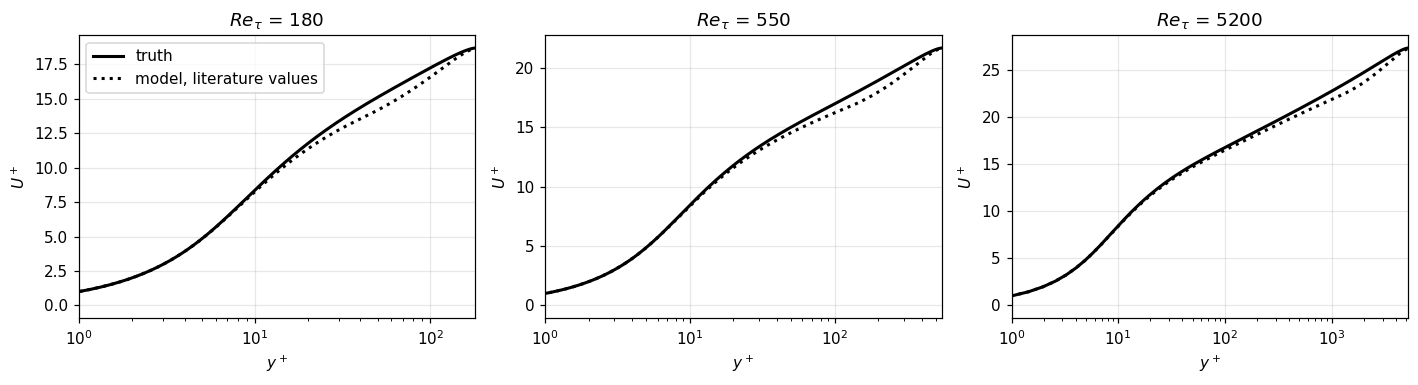

In [2]:
p = np.array([0.41, 26.0, 0.09])       # literature-consistent values
gamma = np.array([0.1, 0.1, 0.1])      # relative uncertainty
NAMES = [r"$\kappa$", r"$A^+$", r"$\lambda$"]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, re in zip(ax, [180, 550, 5200]):
    y, U = truth_profile(re)
    a.semilogx(y, U, "k", lw=2, label="truth")
    a.semilogx(y, model_profile(p, re, y)[1], "k:", lw=2, label="model, literature values")
    a.set(title=f"$Re_\\tau$ = {re}", xlabel="$y^+$", ylabel="$U^+$", xlim=(1, re))
ax[0].legend()
fig.tight_layout()

With the literature values the model is already reasonable: the error sits in the
outer layer and grows with $Re_\tau$. Inferring the parameters at one $Re_\tau$
should reduce it there, and should also improve, or at least not worsen, the
predictions at the other $Re_\tau$.

## 2. Synthetic measurements

We use **5 velocity measurements** at $Re_\tau = 550$, with Gaussian noise of standard
deviation $\sigma_d = 0.3$, so that $\mathbf{C}_{dd} = \sigma_d^2\mathbf{I}$.
$Re_\tau = 180$ and $5200$ are kept as unseen conditions to test the result.

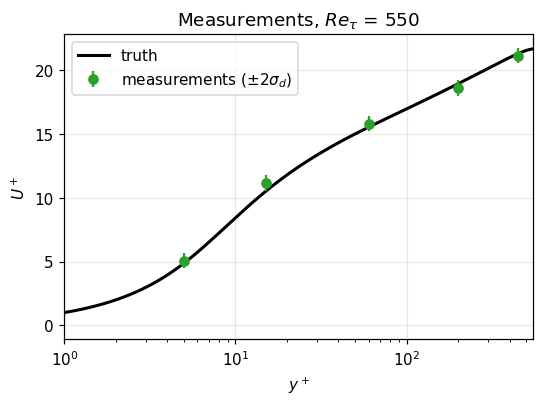

In [3]:
RE_TRAIN, SIGMA_D = 550, 0.3
y_sparse = np.array([5, 15, 60, 200, 450.0])

d_sparse = truth_at(RE_TRAIN, y_sparse) + SIGMA_D * np.random.default_rng(102).standard_normal(y_sparse.size)
forward_sparse = make_forward(RE_TRAIN, y_sparse)   # alpha -> q (U+ at the sensors)

y, U = truth_profile(RE_TRAIN)
fig, a = plt.subplots(figsize=(5.5, 3.6))
a.semilogx(y, U, "k", lw=2, label="truth")
a.errorbar(y_sparse, d_sparse, yerr=2 * SIGMA_D, fmt="o", color="tab:green",
           label="measurements ($\\pm 2\\sigma_d$)")
a.set(xlabel="$y^+$", ylabel="$U^+$", title="Measurements, $Re_\\tau$ = 550", xlim=(1, 550))
a.legend();

## 3. The two filters

Both filters evolve an ensemble of $N$ members. Each member of the augmented state
$\boldsymbol{\psi}$ contains the parameters $\boldsymbol{\alpha} = \mathbf{M}_\alpha\boldsymbol{\psi}$
and the predicted observables $\mathbf{q} = \mathbf{M}_q\boldsymbol{\psi}$. At every
iteration the model is run for each member, and each member is updated to the
minimum of

$$
\mathcal{J}(\boldsymbol{\psi}) =
\left\|\boldsymbol{\psi}^{f} - \boldsymbol{\psi}\right\|^{2}_{(\mathbf{C}^{f}_{\psi\psi})^{-1}}
+ \left\|\mathbf{d} - \mathbf{M}_q\boldsymbol{\psi}\right\|^{2}_{\mathbf{C}_{dd}^{-1}}
+ \left\|\mathbf{p} - \mathbf{M}_\alpha\boldsymbol{\psi}\right\|^{2}_{\mathbf{C}_{pp}^{-1}}.
$$

The three terms penalise departures from the forecast $f$, the misfit to the
measurements, and departures of the parameters from their literature values.
The flow state is not updated directly: it is regenerated by the model from the
updated parameters at the next iteration.

**The standard EnKF** omits the third term, which is the limit
$\mathbf{C}_{pp}\to\infty$. The literature values then enter only through the
initial ensemble, and are forgotten after a few iterations.

**The PR-EnKF** keeps it at every update. In practice the literature values are
appended to the measurements as pseudo-observations of the parameters:

$$
\mathbf{y}_j = \begin{bmatrix} \mathbf{q}_j \\ \boldsymbol{\alpha}_j \end{bmatrix},
\qquad
\tilde{\mathbf{d}}_j = \begin{bmatrix} \mathbf{d} + \boldsymbol{\varepsilon}_j \\
\mathbf{p} \circ \left(\mathbf{1} + \boldsymbol{\gamma} \circ \boldsymbol{\eta}_j\right) \end{bmatrix},
\qquad
\boldsymbol{\varepsilon}_j \sim \mathcal{N}(\mathbf{0}, \mathbf{C}_{dd}),\;
\boldsymbol{\eta}_j \sim \mathcal{N}(\mathbf{0}, \mathbf{I}),
$$

and each member is updated as

$$
\boldsymbol{\alpha}_j \leftarrow \boldsymbol{\alpha}_j
+ \mathbf{C}_{\alpha y}\left(\mathbf{C}_{yy} + \mathbf{C}\right)^{-1}
\left(\tilde{\mathbf{d}}_j - \mathbf{y}_j\right),
\qquad
\mathbf{C} = \begin{bmatrix} \mathbf{C}_{dd} & \\ & \mathbf{C}_{pp} \end{bmatrix},
$$

with covariances estimated from the ensemble and
$C_{pp,ii} = (\gamma_i\,\bar{\alpha}_i)^2$.

The regularisation is adaptive. Parameters well constrained by the measurements
can depart from $\mathbf{p}$, while those for which the data provide limited
information stay close to it.

Implementation choices (normalisation, cross-gain zeroing, fixed perturbations,
inflation) are described in [`docs/theory.md`](../docs/theory.md). In the code, the
two filters differ by a single argument: `regularise=False` gives the standard EnKF.

## 4. Running both filters

Both filters start from the same initial ensemble of 50 members, drawn around the
literature values, and use the same perturbed measurements, the same inflation
($\rho = 1.05$) and 30 iterations.

In [4]:
runs = {name: run(forward_sparse, p, gamma, d_sparse, SIGMA_D, n_ens=50, n_iter=30,
                  regularise=reg, inflation=1.05, seed=2)
        for name, reg in [("EnKF", False), ("PR-EnKF", True)]}

EnKF: forward model failed at iteration 15 (non-physical parameters kappa=0.085, A+=-6.84, lambda=0.169). Stopping.


The EnKF stopped: after 15 iterations, one member reached a negative damping length
$A^+$, which is physically meaningless, and the model could not be evaluated.

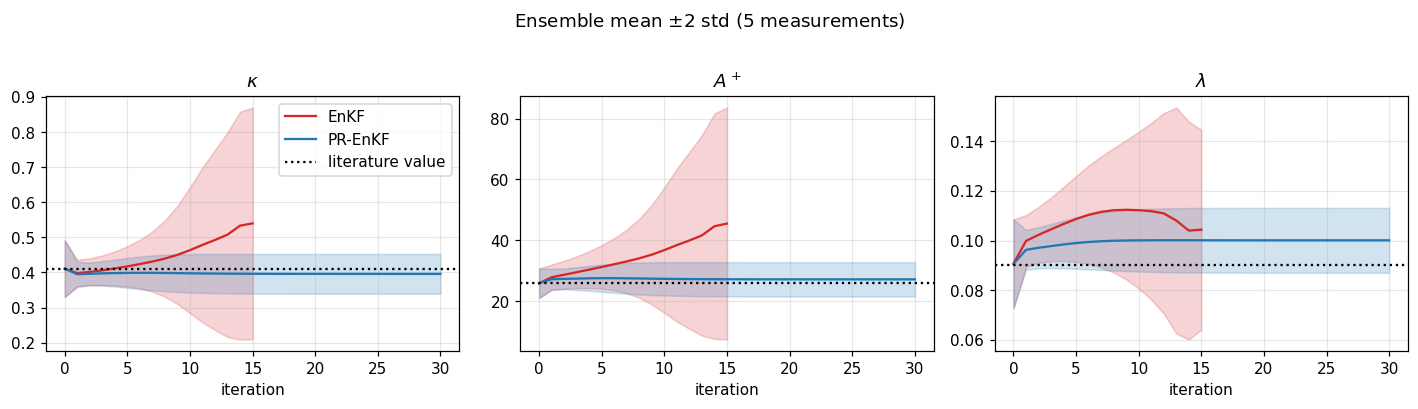

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for name, r in runs.items():
    al = r["alpha"]
    it = np.arange(al.shape[0])
    for i in range(3):
        m, s = al[:, i].mean(1), al[:, i].std(1, ddof=1)
        ax[i].plot(it, m, color=COL[name], label=name)
        ax[i].fill_between(it, m - 2 * s, m + 2 * s, color=COL[name], alpha=0.2)
for i in range(3):
    ax[i].axhline(p[i], color="k", ls=":", label="literature value")
    ax[i].set(title=NAMES[i], xlabel="iteration")
ax[0].legend()
fig.suptitle("Ensemble mean $\\pm 2$ std (5 measurements)", y=1.02)
fig.tight_layout()
save(fig, "parameter_history.png")

The EnKF ensemble does not collapse. Its spread in $\kappa$ and $A^+$ keeps growing,
and its mean moves far from physically reasonable values ($\kappa > 0.5$,
$A^+ > 40$) until members become non-physical. The PR-EnKF settles within a few
iterations, close to, but not at, the literature values.

## 5. Why the EnKF drifts: the ridge

The figure below shows the ensemble in the $(\kappa, A^+)$ plane over the misfit to
the measurements, $\left\|\mathbf{d} - \mathbf{q}\right\|^2_{\mathbf{C}_{dd}^{-1}}$,
with $\lambda$ fixed at its literature value.

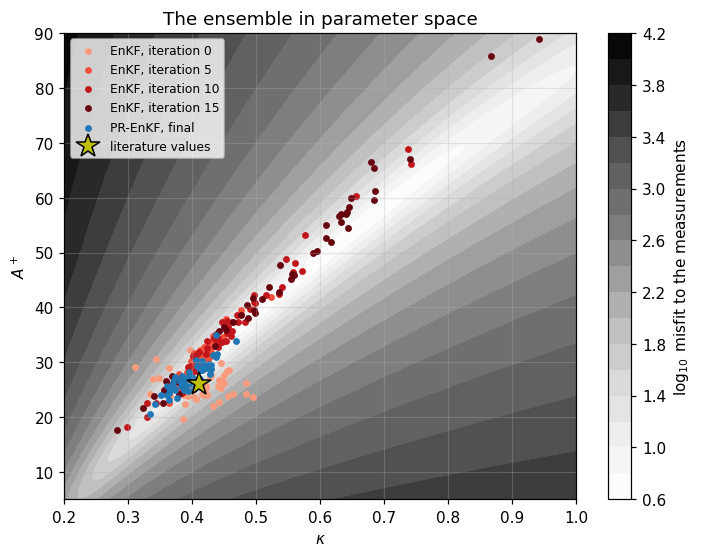

In [6]:
kk, AA = np.meshgrid(np.linspace(0.2, 1.0, 70), np.linspace(5, 90, 70))
J = np.array([[np.sum((forward_sparse((k, A, p[2])) - d_sparse) ** 2) / SIGMA_D**2
               for k, A in zip(rk, rA)] for rk, rA in zip(kk, AA)])

al_e = runs["EnKF"]["alpha"]
snap = [0, 5, 10, al_e.shape[0] - 1]

fig, a = plt.subplots(figsize=(7.5, 5.5))
cs = a.contourf(kk, AA, np.log10(J), levels=20, cmap="Greys")
fig.colorbar(cs, label="$\\log_{10}$ misfit to the measurements")
for i, c in zip(snap, plt.cm.Reds(np.linspace(0.35, 1, len(snap)))):
    a.scatter(al_e[i, 0], al_e[i, 1], s=12, color=c, label=f"EnKF, iteration {i}")
al_p = runs["PR-EnKF"]["alpha"][-1]
a.scatter(al_p[0], al_p[1], s=12, color="tab:blue", label="PR-EnKF, final")
a.plot(*p[:2], "y*", ms=16, mec="k", label="literature values")
a.set(xlabel="$\\kappa$", ylabel="$A^+$", xlim=(0.2, 1.0), ylim=(5, 90),
      title="The ensemble in parameter space")
a.legend(fontsize=8, loc="upper left")
save(fig, "ridge.png")

The light valley is a **ridge of near-equal misfit**. A larger $\kappa$ (larger
mixing length, lower velocity) can be compensated by a larger $A^+$ (thicker damped
layer, higher velocity). Five measurements at a single $Re_\tau$ constrain only this
combination, and the two parameters become almost perfectly correlated in the
ensemble.

Along the ridge, the measurements carry no information. The inflation, which is
needed to prevent the ensemble from collapsing in the directions the data do
constrain, keeps expanding it by 5 % per iteration along the direction they do not.
The EnKF has nothing to counteract this, and the ensemble slides along the valley
until members become non-physical.

The PR-EnKF uses the same measurements and the same inflation. The pseudo-observations
of the literature values constrain the direction the measurements cannot see, so the
ensemble stays near the physically plausible end of the valley.

> A low misfit to the measurements does not imply correct parameters. Where the data
> provide limited information, the literature values are the only information
> available.

## 6. Predictions at unseen conditions

Most EnKF runs do not fail: they stop somewhere along the ridge instead. To see why
that is still a problem, we use a layout where both filters converge: **8 measurements
in the outer region**, again at $Re_\tau = 550$.

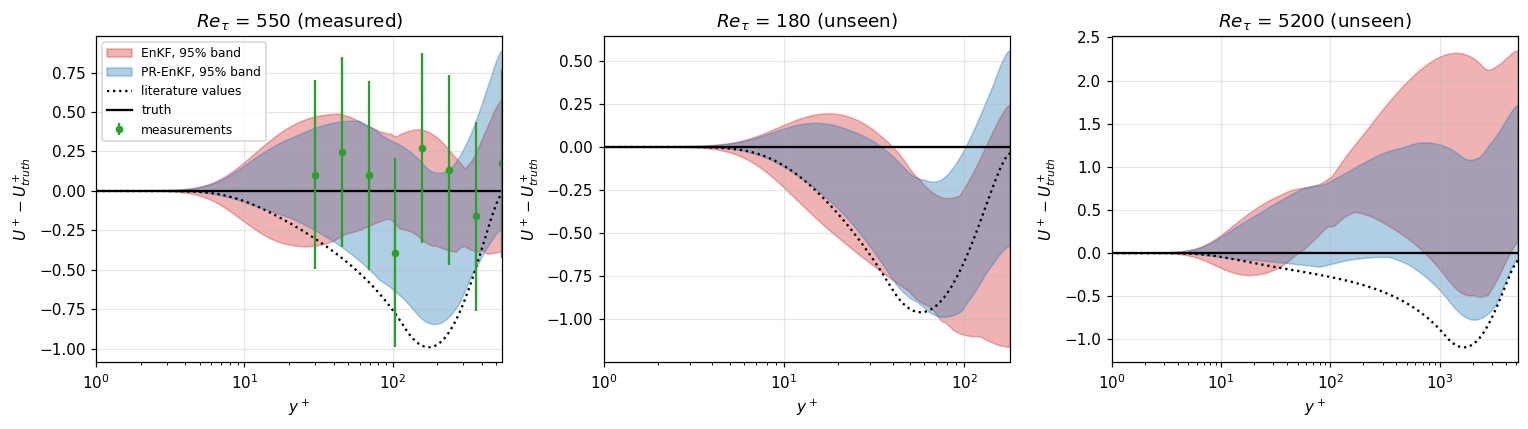

In [7]:
y_outer = np.geomspace(30, 550, 8)
d_outer = truth_at(RE_TRAIN, y_outer) + SIGMA_D * np.random.default_rng(1).standard_normal(y_outer.size)
forward_outer = make_forward(RE_TRAIN, y_outer)

runs_outer = {name: run(forward_outer, p, gamma, d_outer, SIGMA_D, n_ens=50, n_iter=30,
                        regularise=reg, inflation=1.05, seed=0)
              for name, reg in [("EnKF", False), ("PR-EnKF", True)]}

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, re in zip(ax, [550, 180, 5200]):
    y, U = truth_profile(re)
    for name, r in runs_outer.items():
        Q = np.array([model_profile(al, re, y)[1] for al in r["alpha"][-1].T])
        lo, hi = np.percentile(Q, [2.5, 97.5], axis=0)
        a.fill_between(y, lo - U, hi - U, color=COL[name], alpha=0.35, label=f"{name}, 95% band")
    a.plot(y, model_profile(p, re, y)[1] - U, "k:", label="literature values")
    a.axhline(0, color="k", lw=1.5, label="truth")
    if re == RE_TRAIN:
        a.errorbar(y_outer, d_outer - truth_at(re, y_outer), yerr=2 * SIGMA_D, fmt="o",
                   color="tab:green", ms=4, label="measurements")
    a.set_xscale("log")
    a.set(title=f"$Re_\\tau$ = {re}" + (" (measured)" if re == RE_TRAIN else " (unseen)"),
          xlabel="$y^+$", ylabel="$U^+ - U^+_{truth}$", xlim=(1, re))
ax[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "generalisation.png")

The plots show the error with respect to the truth: the black line at zero is perfect
agreement. At the training $Re_\tau$ both filters do well. At $Re_\tau = 5200$ the EnKF
band moves away from zero and over-predicts the velocity in the outer layer: a
combination of parameters that compensates at $Re_\tau = 550$ no longer compensates
when the outer layer is thicker. The PR-EnKF band stays around zero over most of the
profile.

The table below separates two quantities that are easy to confuse: the misfit to the
noisy measurements, and the error with respect to the truth.

In [8]:
def error_vs_truth(alpha, re):
    y, U = truth_profile(re)
    return np.sqrt(np.mean((model_profile(alpha, re, y)[1] - U) ** 2))

def misfit(alpha):
    return np.sqrt(np.mean((forward_outer(alpha) - d_outer) ** 2))

rows = [("literature values", p)] + [(n, r["alpha"][-1].mean(1)) for n, r in runs_outer.items()]
print(f"{'':18s} {'misfit to data':>15s} {'error, Re=550':>14s} {'error, Re=180':>14s} {'error, Re=5200':>15s}")
for name, al in rows:
    print(f"{name:18s} {misfit(al):15.2f} {error_vs_truth(al, 550):14.2f} "
          f"{error_vs_truth(al, 180):14.2f} {error_vs_truth(al, 5200):15.2f}")
print(f"\nnoise level sigma_d = {SIGMA_D}")

                    misfit to data  error, Re=550  error, Re=180  error, Re=5200
literature values             0.71           0.59           0.55            0.68
EnKF                          0.24           0.09           0.54            1.07
PR-EnKF                       0.28           0.17           0.31            0.44

noise level sigma_d = 0.3


The EnKF reaches a misfit **below the noise level** $\sigma_d$: it is fitting the noise.
The PR-EnKF accepts a misfit close to $\sigma_d$, as expected for a fit consistent
with the measurement uncertainty.

In this realisation the EnKF is even closer to the truth at the training $Re_\tau$:
the extra freedom it takes is not necessarily wrong where the data were measured.
The cost appears elsewhere. At $Re_\tau = 5200$ its error exceeds that of the model
with literature values, while the PR-EnKF improves on it at both unseen conditions.

## 7. Summary

| | EnKF | PR-EnKF |
|---|---|---|
| Literature values | initial ensemble only | assimilated at every update |
| Directions not constrained by the data | drift, amplified by inflation | held near $\mathbf{p}$ |
| Misfit to the measurements | below the noise level | close to the noise level |
| Predictions at unseen conditions | can be worse than the literature values | improved |
| Uncertainty | overconfident | better coverage of the truth |

The extra cost of the PR-EnKF is negligible: $n_\alpha$ additional rows in the
observation vector.

To check that these conclusions do not depend on one noise realisation, run
`python scripts/statistics.py`, which repeats the comparison over 30 realisations
(results in the [README](../README.md)).

## 8. Exercises

1. **Remove inflation** (`inflation=1.0`). Does the EnKF still fail? Where on the
   ridge does it stop, and does that depend on the noise realisation?
2. **Add measurements**, e.g. 20 points between $y^+ = 2$ and $550$. Does the
   difference between the two filters shrink? Why?
3. **Change $\boldsymbol{\gamma}$** to 0.02 or 0.5. What happens when the literature
   values are trusted too much, or too little?
4. **Use two Reynolds numbers at once** by stacking two forward models. Does the
   EnKF still drift? (Hint: the ridge has a different orientation at each $Re_\tau$.)
5. **Use a wrong literature value**, e.g. $p_\kappa = 0.30$. How far do the
   measurements pull the PR-EnKF away from it?

## 9. Going further

The OpenFOAM implementation in [`openfoam/`](../openfoam) applies the same update
with each ensemble member being a full simulation. It supports multiple domains,
multiple observed fields, parameter clustering and HPC execution, and is not tied
to a specific type of model. [`docs/theory.md`](../docs/theory.md) gives the full
algorithm and the correspondence between the two implementations.